<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%206/MRayhanZamzami_JS06_Regresi_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 2 - Support Vector Regression (SVR) dengan Kernel RBF

Dataset: Posisi_gaji.csv (prediksi gaji berdasarkan tingkat posisi).

## Langkah 1 - Import Library dan Dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Baca dataset
dataset = pd.read_csv('dataset/Posisi_gaji.csv')
dataset.head()

,Posisi,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [2]:
# Pisahkan fitur dan target
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values
print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (10, 1)
Shape y: (10,)


## Langkah 2 - Feature Scaling

In [3]:
from sklearn.preprocessing import StandardScaler

# SVM sangat sensitif terhadap skala data
sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X)
y_scaled = sc_y.fit_transform(y.reshape(-1, 1)).ravel()

## Langkah 3 - Fitting Model SVR

In [4]:
from sklearn.svm import SVR

regressor = SVR(kernel='rbf')
regressor.fit(X_scaled, y_scaled)
print('Model SVR berhasil dilatih')

Model SVR berhasil dilatih


## Langkah 4 - Visualisasi Hasil SVR

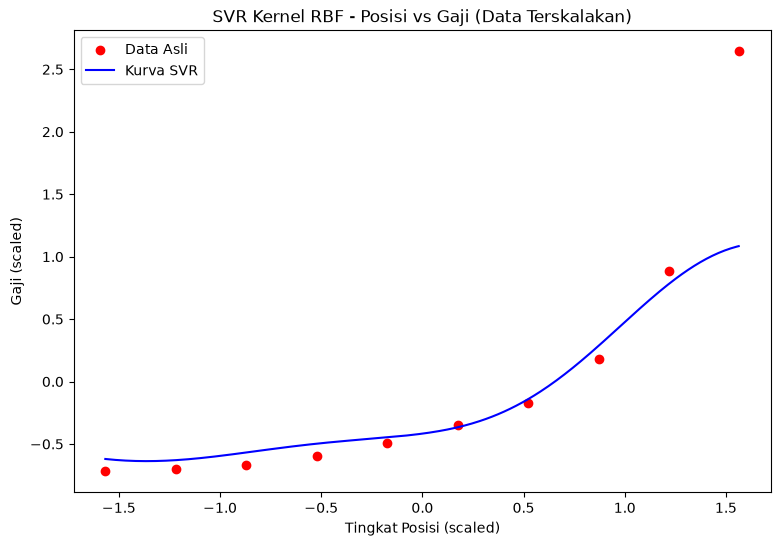

In [5]:
# Grid halus untuk kurva SVR
X_grid = np.arange(float(X_scaled.min()), float(X_scaled.max()), 0.01).reshape(-1, 1)

plt.figure(figsize=(9, 6))
plt.scatter(X_scaled, y_scaled, color='red', label='Data Asli')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', label='Kurva SVR')
plt.title('SVR Kernel RBF - Posisi vs Gaji (Data Terskalakan)')
plt.xlabel('Tingkat Posisi (scaled)')
plt.ylabel('Gaji (scaled)')
plt.legend()
plt.show()

## Langkah 5 - Prediksi Tingkat Posisi 6.5

In [6]:
# Prediksi gaji pada tingkat posisi 6.5
tingkat_posisi_prediksi = np.array([[6.5]])
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

print('Prediksi Gaji untuk Tingkat Posisi 6.5:', gaji_prediksi[0][0])

Prediksi Gaji untuk Tingkat Posisi 6.5: 170370.02040650236


## Langkah 6 - Evaluasi Model SVR

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada skala target asli (lebih mudah diinterpretasikan)
y_actual = y
y_pred_scaled = regressor.predict(X_scaled)
y_pred = sc_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print('MAE :', mae)
print('MSE :', mse)
print('RMSE:', rmse)
print('R-squared:', r2)

MAE : 63332.392089689674
MSE : 20036494264.13176
RMSE: 141550.3241399742
R-squared: 0.7516001070620797


In [8]:
# Evaluasi pada skala standar (sesuai modul)
mae_s = mean_absolute_error(y_scaled, y_pred_scaled)
mse_s = mean_squared_error(y_scaled, y_pred_scaled)
r2_s = r2_score(y_scaled, y_pred_scaled)
print('MAE (scaled) :', mae_s)
print('MSE (scaled) :', mse_s)
print('RMSE (scaled):', np.sqrt(mse_s))
print('R2 (scaled)  :', r2_s)

MAE (scaled) : 0.22299274095734414
MSE (scaled) : 0.24839989293792014
RMSE (scaled): 0.4983973243687411
R2 (scaled)  : 0.7516001070620798
